In [1]:
import pathlib
import sys
module_dir = pathlib.Path("").parent.resolve()
root_dir = module_dir.parent
asvlite_wrapper_dir = root_dir.joinpath("dependency", "ASVLite", "wrapper", "cython")
sys.path.insert(0, str(asvlite_wrapper_dir))

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
from geometry import py_Coordinates_3D
from sea_surface import py_Sea_surface
from asv import py_Asv
from utils import *

plt.rcParams['figure.figsize'] = [18, 5]

## 1 - Global Variables

In [3]:
# Sea surface variables
wave_hs = 1.2 # Significant wave height in m
wave_dp = math.pi/3 # wave direction of propagation 45 deg N

# ASV start position and attitude
start_attitude = py_Coordinates_3D(0.0, 0.0, 0.0) # Both ASVs will have the same initial attitude
position_1 = py_Coordinates_3D(100.0, 100.0)
position_2 = py_Coordinates_3D(3000.0, 3000.0)

## 2 - Sync motion in a regular wave

- asv_1 and asv_2 placed at two different locations.
- Both asvs will collect the sea surface elevations at its location.
- The sea surface consist of only a single regular wave.
- The asvs will then compute the perdominant wave frequency using FFT and will move to a new position to synchronise there heave motions. 
- The new position will be computed from the intial position moving along the direction of propagation of the predominant swell.

In [4]:
# Sea surface
count_component_waves = 1
sea_surface = py_Sea_surface(wave_hs, wave_dp, wave_rand_seed, count_component_waves)

In [5]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [6]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

Text(0, 0.5, 'Sea surface elevation (m)')

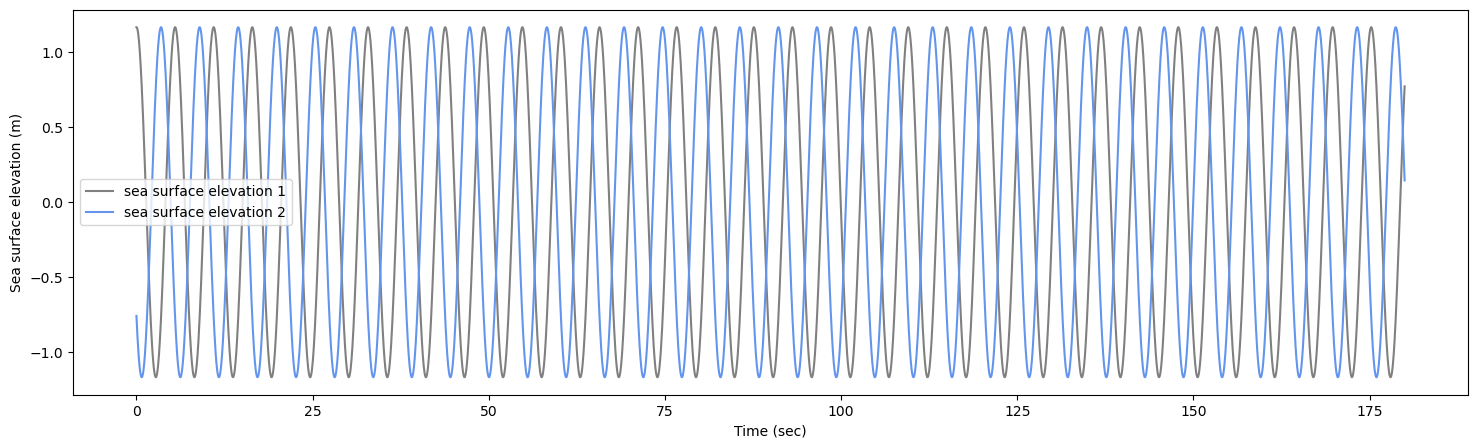

In [7]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()
plt.xlabel("Time (sec)")
plt.ylabel("Sea surface elevation (m)")

In [8]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  2.0
Avg of peak diff =  1.99875


Text(0, 0.5, 'Y (m)')

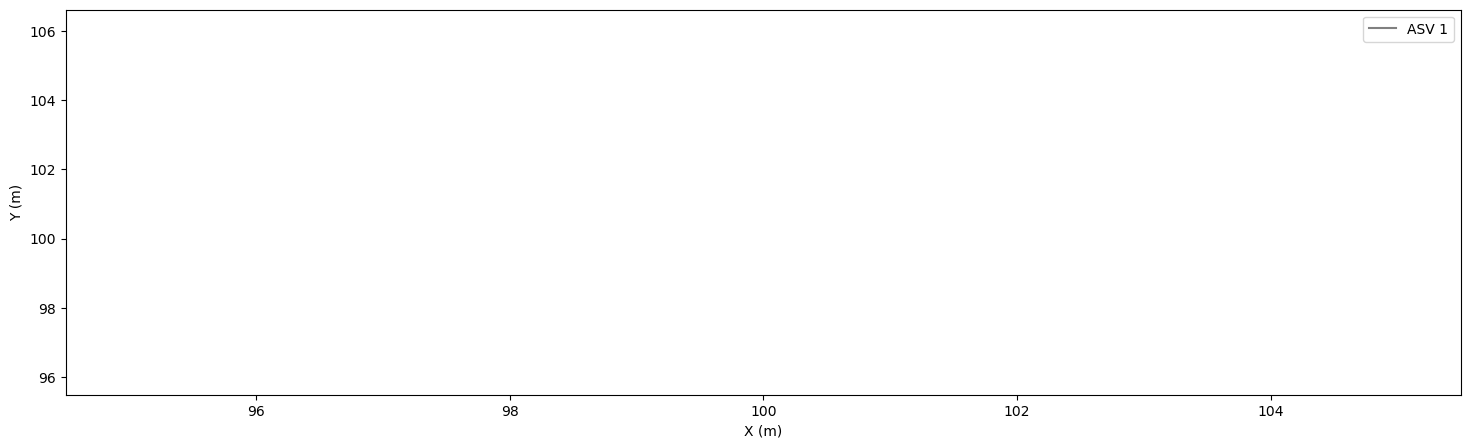

In [9]:
# Plot the ASVs paths. It should not be moving. 
plt.plot([position.x for position in positions_1], [position.y for position in positions_1], label="ASV 1", color="grey")
plt.legend()
plt.xlabel("X (m)")
plt.ylabel("Y (m)")

**_Note_**: *An emply plot here is good. It indicates the ASV did not move.*

Text(0, 0.5, 'Y (m)')

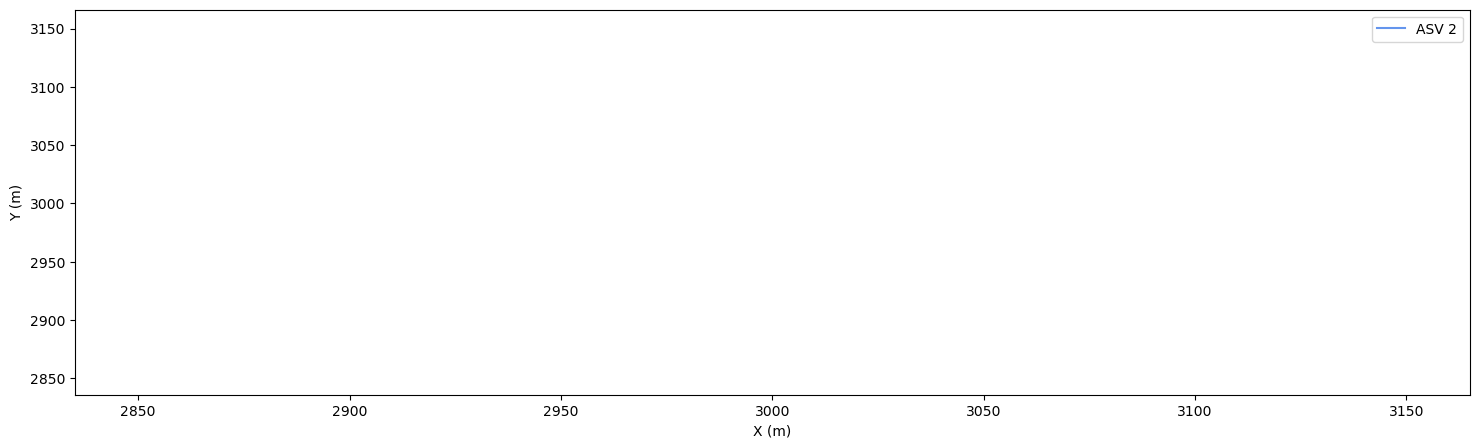

In [10]:
# Plot the ASVs paths. It should not be moving. 
plt.plot([position.x for position in positions_2], [position.y for position in positions_2], label="ASV 2", color="cornflowerblue")
plt.legend()
plt.xlabel("X (m)")
plt.ylabel("Y (m)")

**_Note_**: *An emply plot here is good. It indicates the ASV did not move.*

Text(0, 0.5, 'Frequency')

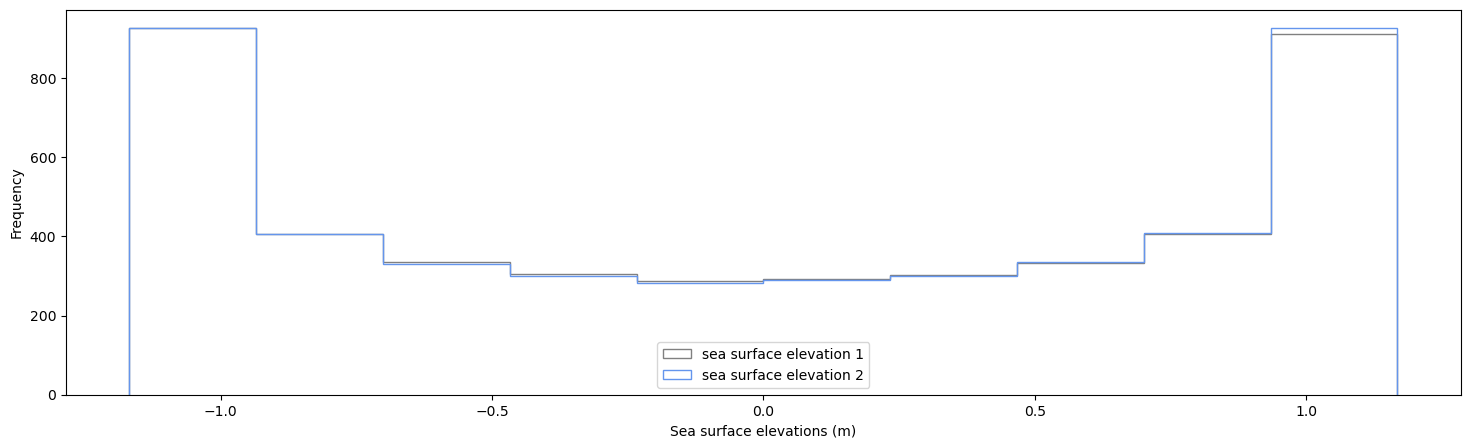

In [11]:
plt.hist(elevations_1, histtype=u'step', label="sea surface elevation 1", color="grey")
plt.hist(elevations_2, histtype=u'step', label="sea surface elevation 2", color="cornflowerblue")
plt.legend()
plt.xlabel("Sea surface elevations (m)")
plt.ylabel("Frequency")

### 2.1 - Estimate frequency

In [12]:
L_1, fhat_1, freq_1, PSD_1, i_max_1 = fast_fourier_transform(elevations_1)
L_2, fhat_2, freq_2, PSD_2, i_max_2 = fast_fourier_transform(elevations_2)

/home/toby/micromamba/envs/seasyncsquad/lib/python3.11/site-packages/matplotlib/cbook/__init__.py:1340: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


Text(0, 0.5, 'Power Spectral Density')

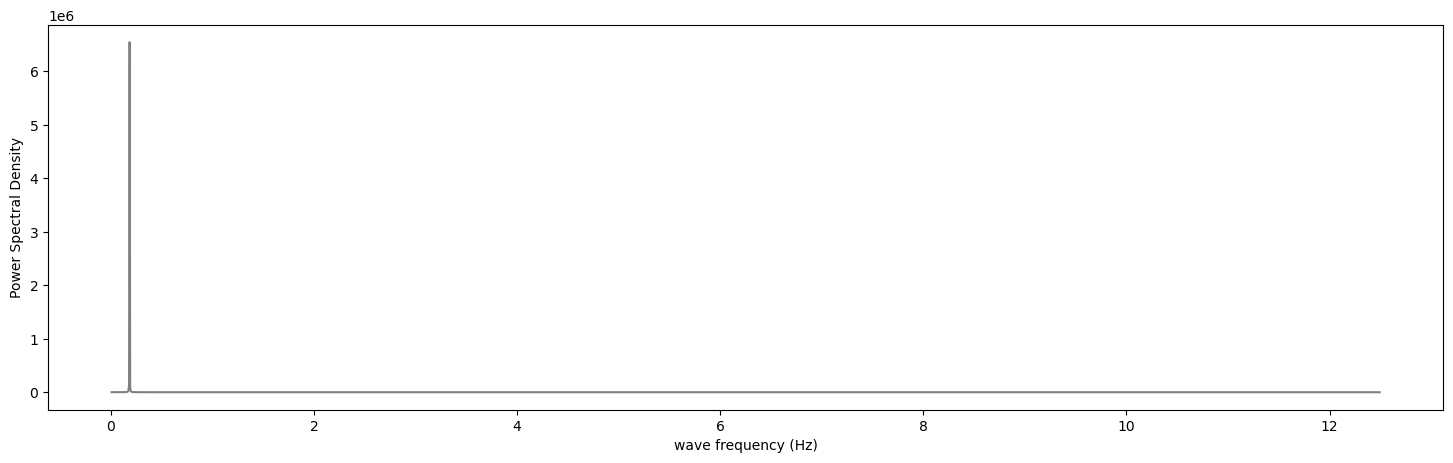

In [13]:
plt.plot(freq_1[L_1], PSD_1[L_1], color="grey")
plt.xlabel("wave frequency (Hz)")
plt.ylabel("Power Spectral Density")

Text(0, 0.5, 'Power Spectral Density')

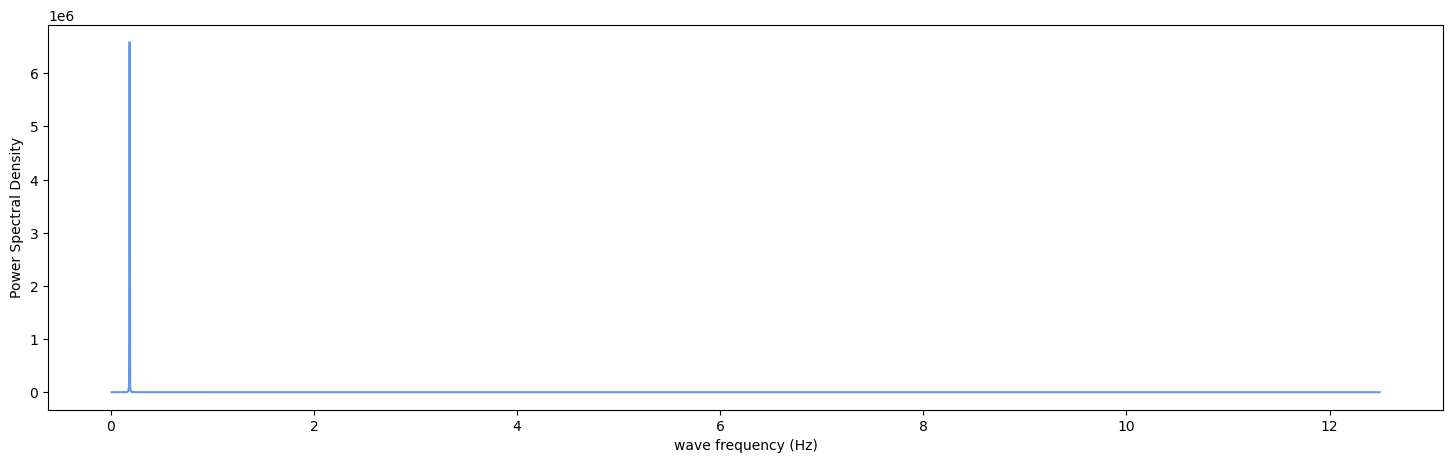

In [14]:
plt.plot(freq_2[L_2], PSD_2[L_2], color="cornflowerblue")
plt.xlabel("wave frequency (Hz)")
plt.ylabel("Power Spectral Density")

In [15]:
f_max_1 = abs(freq_1[i_max_1])
f_max_2 = abs(freq_2[i_max_2])
print("Peak freq for ASV_1 = ", f_max_1)
print("Peak freq for ASV_2 = ", f_max_2)

Peak freq for ASV_1 =  0.18333333333333335
Peak freq for ASV_2 =  0.18333333333333335


In [16]:
sea_surface.py_get_peak_spectral_frequency()

0.18263810872998018

### 2.2 - Find the nearest positions to move using estimated frequency

In [17]:
new_position_1 = get_new_position(wave_dp, position_1, f_max_1)
print("py_Coordinate_3D({}, {})".format(new_position_1.x, new_position_1.y))

new_position_2 = get_new_position(wave_dp, position_2, f_max_2)
print("py_Coordinate_3D({}, {})".format(new_position_2.x, new_position_2.y))

py_Coordinate_3D(102.385009765625, 101.3770751953125)
py_Coordinate_3D(2991.0948486328125, 2994.858642578125)


### 2.3 - Simulate with new positions (estimated frequency)

In [18]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, new_position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, new_position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [19]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

Text(0, 0.5, 'Sea surface elevation (m)')

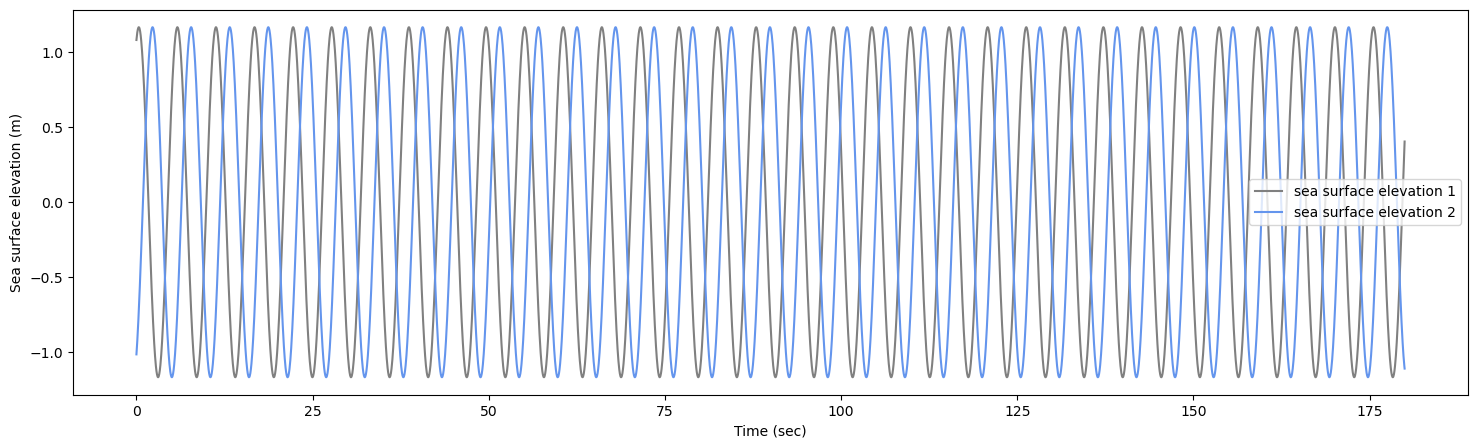

In [20]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()
plt.xlabel("Time (sec)")
plt.ylabel("Sea surface elevation (m)")

In [21]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  1.96
Avg of peak diff =  1.9527272727272726


### 2.4 - Find the nearest positions to move using actual frequency

In [22]:
new_position_1 = get_new_position(wave_dp, position_1, sea_surface.py_get_peak_spectral_frequency())
print("py_Coordinate_3D({}, {})".format(new_position_1.x, new_position_1.y))

new_position_2 = get_new_position(wave_dp, position_2, sea_surface.py_get_peak_spectral_frequency())
print("py_Coordinate_3D({}, {})".format(new_position_2.x, new_position_2.y))

py_Coordinate_3D(103.3055419921875, 101.90850830078125)
py_Coordinate_3D(3018.09765625, 3010.44873046875)


### 2.5 - Simulate with new positions (actual frequency)

In [23]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, new_position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, new_position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [24]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

Text(0, 0.5, 'Sea surface elevation (m)')

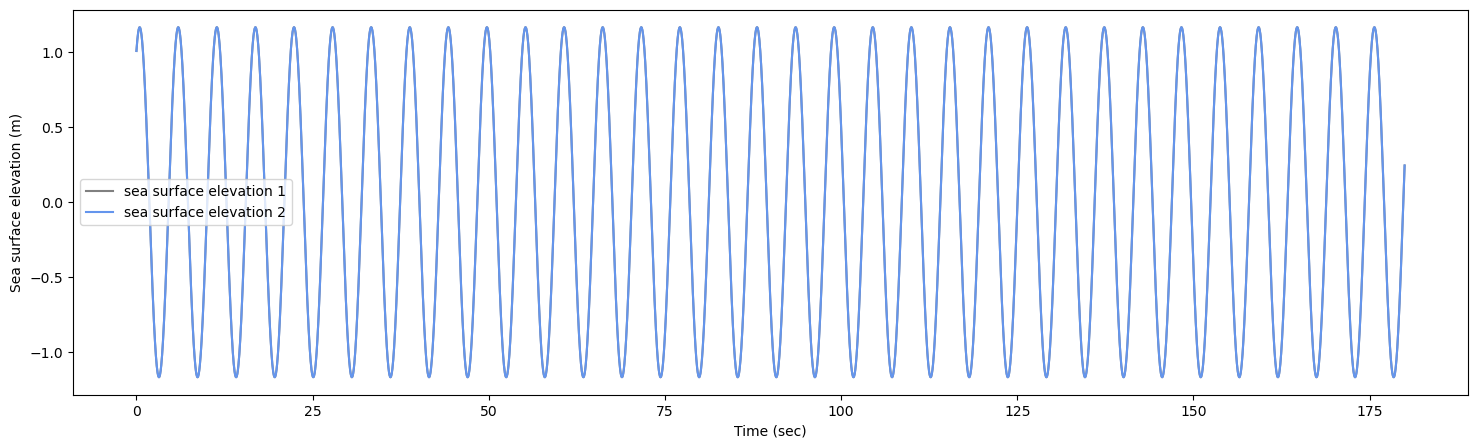

In [25]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()
plt.xlabel("Time (sec)")
plt.ylabel("Sea surface elevation (m)")

In [26]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  0.0
Avg of peak diff =  0.0


## 3 - Sync motion in a irregular wave
- Same as the previous experiment but using an irregular sea surface.

In [27]:
# Sea surface
count_component_waves = 21
sea_surface = py_Sea_surface(wave_hs, wave_dp, wave_rand_seed, count_component_waves)

In [28]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [29]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

Text(0, 0.5, 'Sea surface elevation (m)')

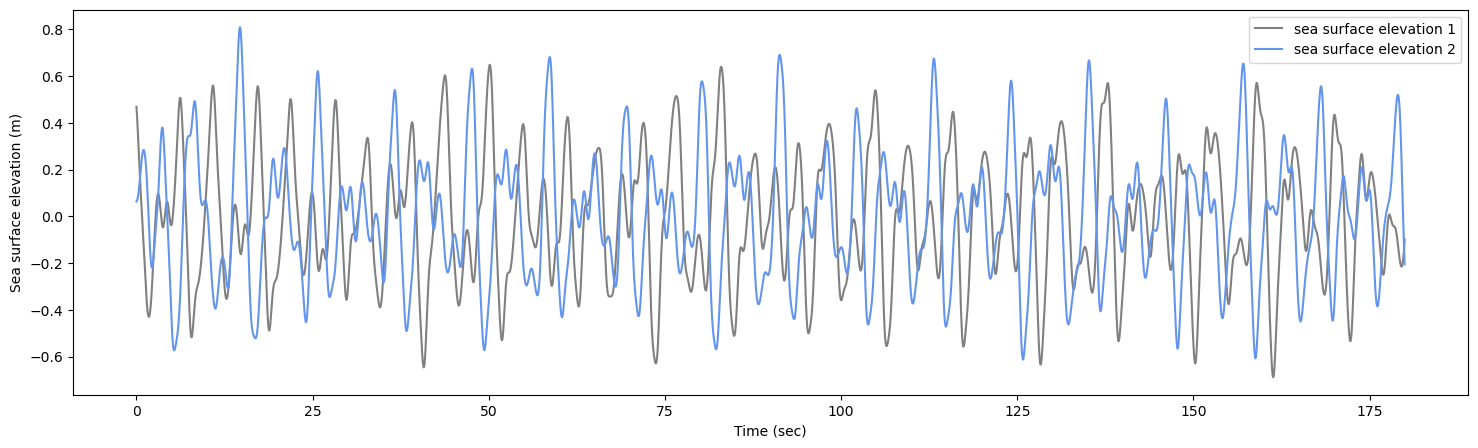

In [30]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()
plt.xlabel("Time (sec)")
plt.ylabel("Sea surface elevation (m)")

In [31]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  23.76
Avg of peak diff =  15.292173913043479


Text(0, 0.5, 'Y (m)')

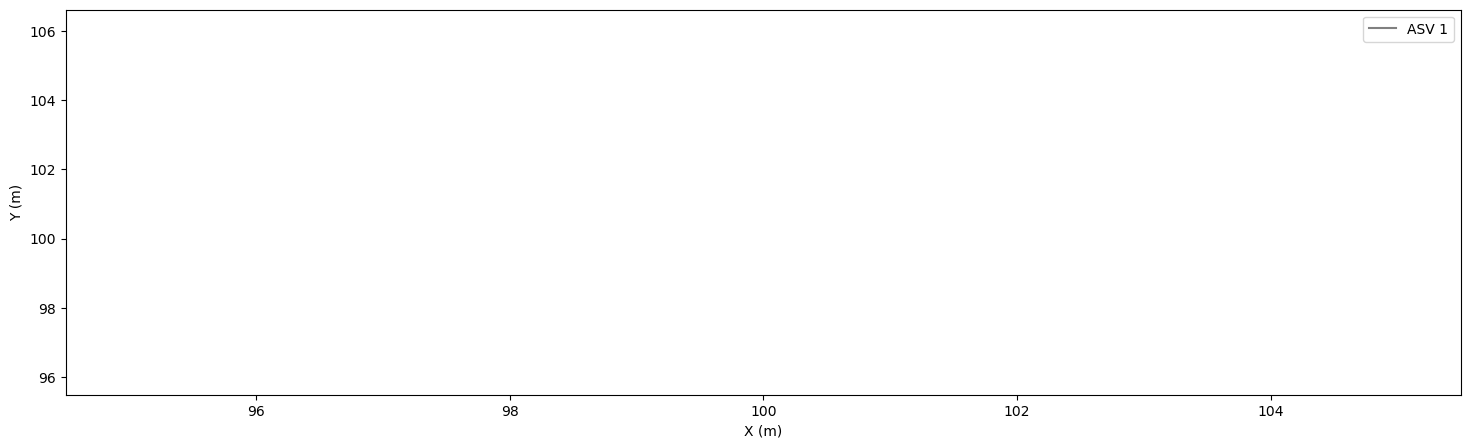

In [32]:
# Plot the ASVs paths. It should not be moving. 
plt.plot([position.x for position in positions_1], [position.y for position in positions_1], label="ASV 1", color="grey")
plt.legend()
plt.xlabel("X (m)")
plt.ylabel("Y (m)")

**_Note_**: *An emply plot here is good. It indicates the ASV did not move.*

Text(0, 0.5, 'Y (m)')

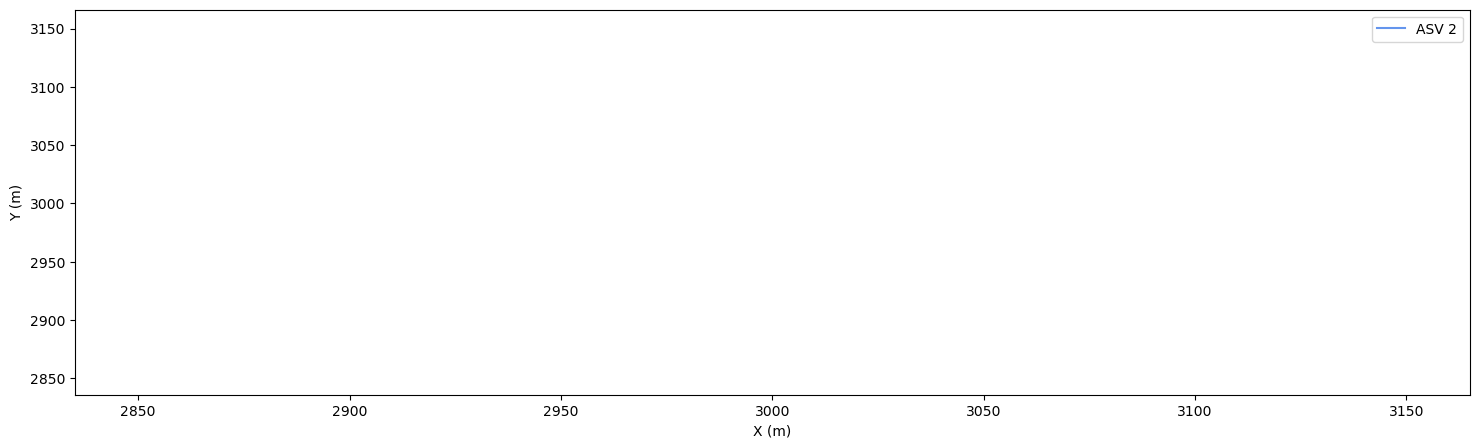

In [33]:
# Plot the ASVs paths. It should not be moving. 
plt.plot([position.x for position in positions_2], [position.y for position in positions_2], label="ASV 2", color="cornflowerblue")
plt.legend()
plt.xlabel("X (m)")
plt.ylabel("Y (m)")

**_Note_**: *An emply plot here is good. It indicates the ASV did not move.*

Text(0, 0.5, 'Frequency')

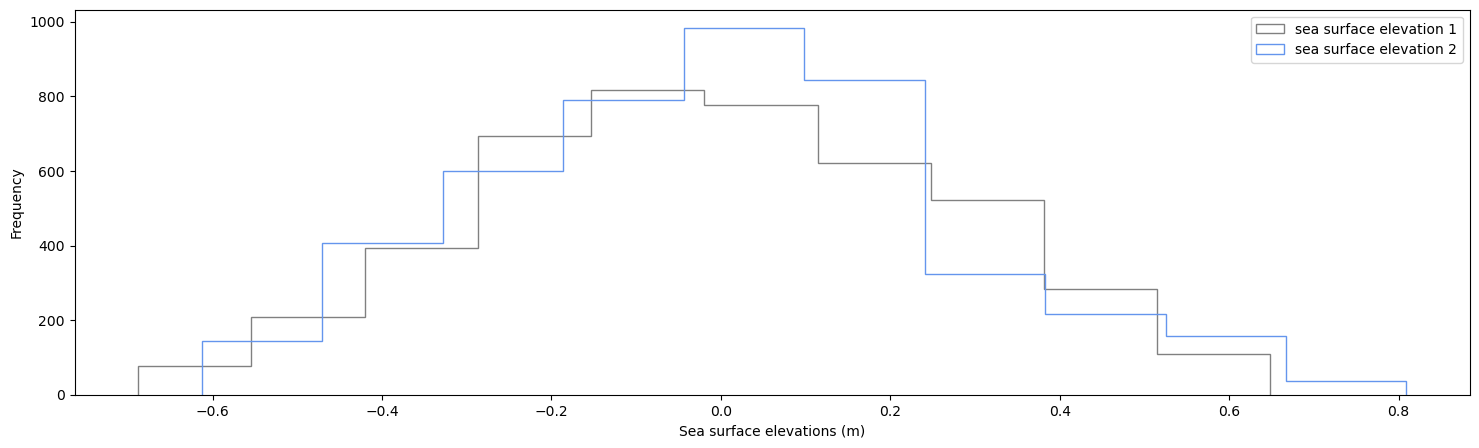

In [34]:
plt.hist(elevations_1, histtype=u'step', label="sea surface elevation 1", color="grey")
plt.hist(elevations_2, histtype=u'step', label="sea surface elevation 2", color="cornflowerblue")
plt.legend()
plt.xlabel("Sea surface elevations (m)")
plt.ylabel("Frequency")

### 3.1 - Estimate frequency

In [35]:
L_1, fhat_1, freq_1, PSD_1, i_max_1 = fast_fourier_transform(elevations_1)
L_2, fhat_2, freq_2, PSD_2, i_max_2 = fast_fourier_transform(elevations_2)

Text(0, 0.5, 'Power Spectral Density')

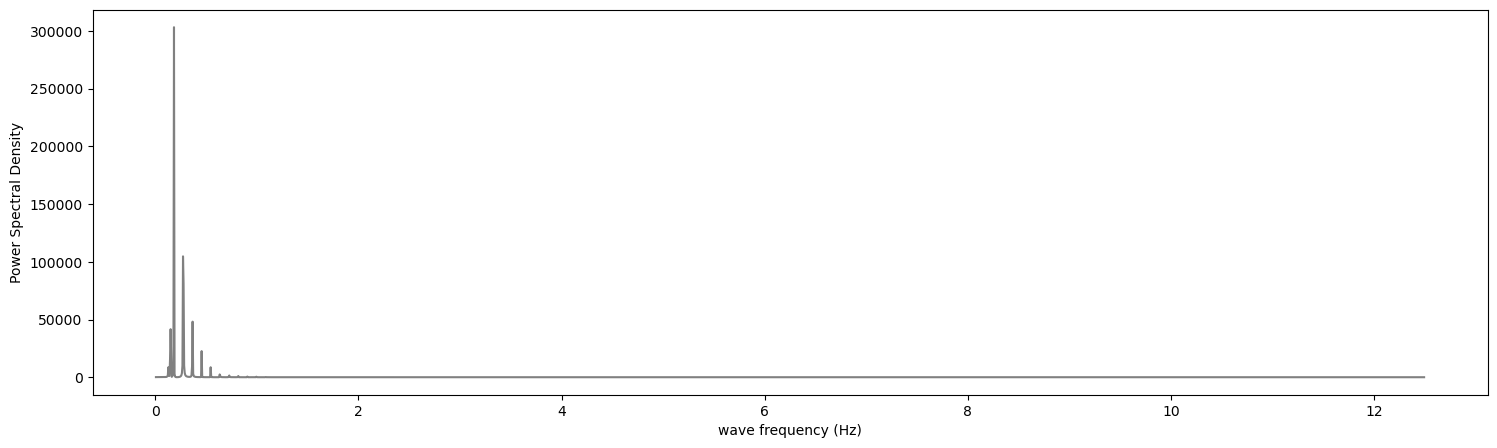

In [36]:
plt.plot(freq_1[L_1], PSD_1[L_1], color="grey")
plt.xlabel("wave frequency (Hz)")
plt.ylabel("Power Spectral Density")

Text(0, 0.5, 'Power Spectral Density')

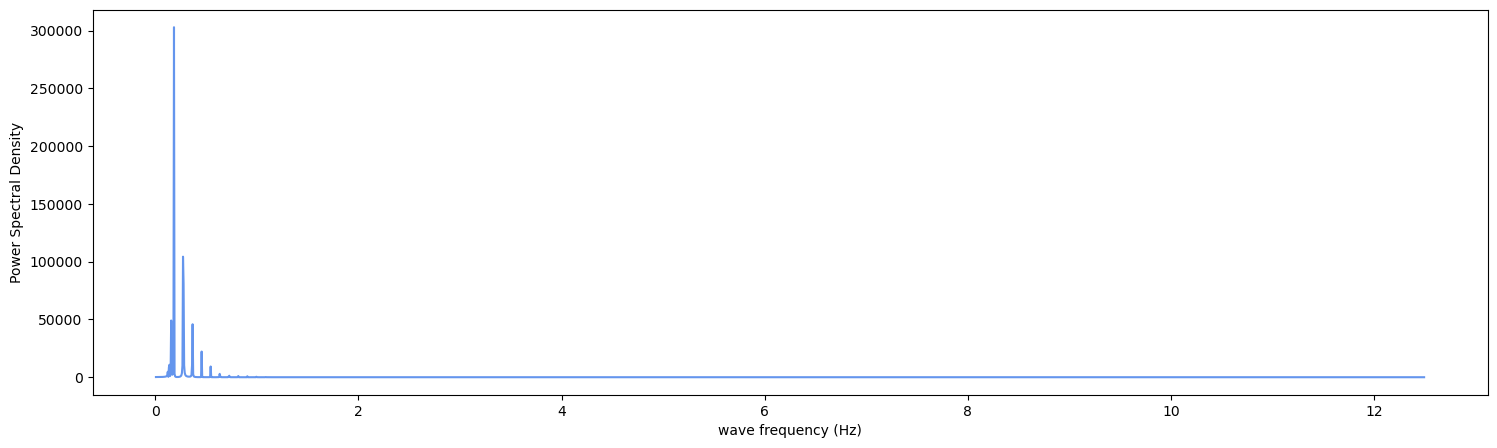

In [37]:
plt.plot(freq_2[L_2], PSD_2[L_2], color="cornflowerblue")
plt.xlabel("wave frequency (Hz)")
plt.ylabel("Power Spectral Density")

In [38]:
f_max_1 = abs(freq_1[i_max_1])
f_max_2 = abs(freq_2[i_max_2])
print("Peak freq for ASV_1 = ", f_max_1)
print("Peak freq for ASV_2 = ", f_max_2)

Peak freq for ASV_1 =  0.18333333333333335
Peak freq for ASV_2 =  0.18333333333333335


In [39]:
sea_surface.py_get_peak_spectral_frequency()

0.18263810872998018

### 3.2 - Find the nearest positions to move using estimated frequency

In [40]:
new_position_1 = get_new_position(wave_dp, position_1, f_max_1)
print("py_Coordinate_3D({}, {})".format(new_position_1.x, new_position_1.y))

new_position_2 = get_new_position(wave_dp, position_2, f_max_2)
print("py_Coordinate_3D({}, {})".format(new_position_2.x, new_position_2.y))

py_Coordinate_3D(102.385009765625, 101.3770751953125)
py_Coordinate_3D(2991.0948486328125, 2994.858642578125)


### 3.3 - Simulate with new positions (estimated frequency)

In [41]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, new_position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, new_position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [42]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

Text(0, 0.5, 'Sea surface elevation (m)')

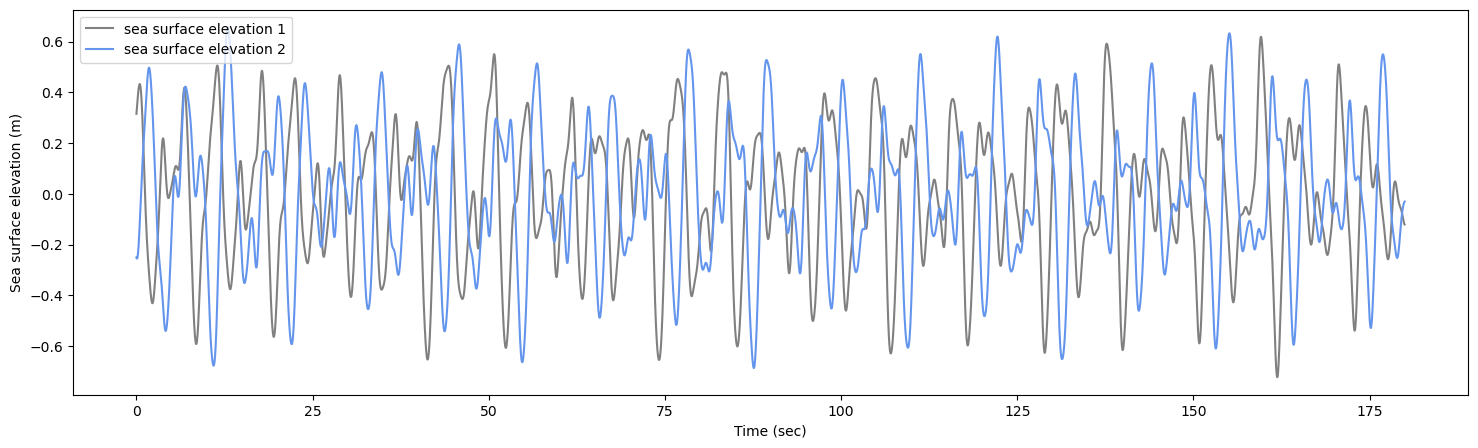

In [43]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()
plt.xlabel("Time (sec)")
plt.ylabel("Sea surface elevation (m)")

In [44]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  24.32
Avg of peak diff =  9.99761194029851


### 3.4 - Find the nearest positions to move using actual frequency

In [45]:
new_position_1 = get_new_position(wave_dp, position_1, sea_surface.py_get_peak_spectral_frequency())
print("py_Coordinate_3D({}, {})".format(new_position_1.x, new_position_1.y))

new_position_2 = get_new_position(wave_dp, position_2, sea_surface.py_get_peak_spectral_frequency())
print("py_Coordinate_3D({}, {})".format(new_position_2.x, new_position_2.y))

py_Coordinate_3D(103.3055419921875, 101.90850830078125)
py_Coordinate_3D(3018.09765625, 3010.44873046875)


### 3.5 - Simulate with new positions (actual frequency)

In [46]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, new_position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, new_position_2, start_attitude)
# Ensure the ASVs does not surge or sway
asv_1.py_set_surge_sway_halt(True)
asv_2.py_set_surge_sway_halt(True)

In [47]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

Text(0, 0.5, 'Sea surface elevation (m)')

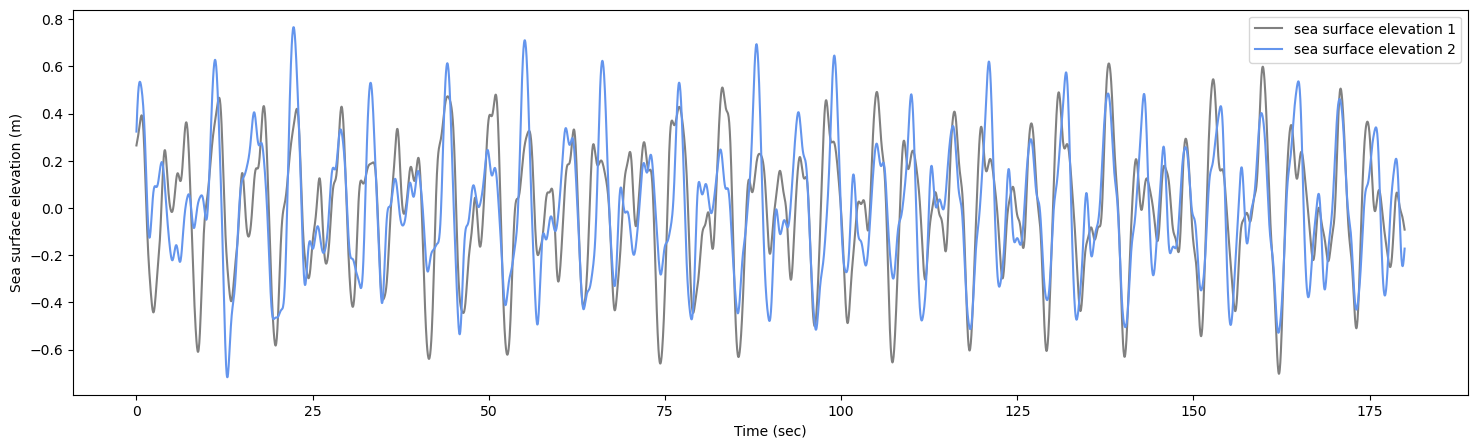

In [48]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(np.arange(0, time_duration, time_step_size/1000), elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()
plt.xlabel("Time (sec)")
plt.ylabel("Sea surface elevation (m)")

In [49]:
peak_diffs = peak_time_diffs(elevations_1, elevations_2)
print("Max time diff = ", np.abs(peak_diffs).max())
print("Avg of peak diff = ", np.abs(peak_diffs).mean())

Max time diff =  11.28
Avg of peak diff =  6.208695652173914


## 4 - Key Observations

- Positioning the ASVs relative to a reference point, using multiples of the wave length, proves effective in both regular and irregular wave scenarios.
- The efficacy of this method heavily depends on the precise estimation of the wave frequency.
- In our tests, there was a slight discrepancy between the actual and estimated frequencies, observed in both regular and irregular waves.
- Given that the two ASVs were spaced approximately 3000 m apart, this error, over such long distances, led to a desynchronisation of the ASVs.
- Importantly, when the ASVs were aligned using the true peak wave frequencies, synchronisation was achieved flawlessly.
- In the current experiments, with a brief time window of 3 minutes, it was feasible to visually compare the synchronisation of the wave trains. However, this visual method becomes impractical as the time window expands. We addressed this by calculating the average time differences between peaks, which proved to be a reliable index. A high value signifies out-of-sync waves, whilst a value of 0 indicates perfectly synchronised regular waves. For irregular waves, a low value also suggests synchronisation, but it's worth noting that it won't be precisely zero. This is because the method primarily targets the synchronisation of dominant swells, meaning smaller peaks might not always align.